# MLP_JK_08 — Gene selection: which genes can the images actually predict?

**Why this notebook (Task 2):** so far every score is an average over the 50 most variable genes. Some genes don't change what the tissue looks like, so the average may hide the genes that do work. Here we find the genes that are predictable from the H&E embeddings, choosing them on **validation patients only**, and check whether they stay predictable on **new (test) patients**.

**Setup** (the same as MLP_JK_03/07 unless stated)
- RAW target, `log1p(count)` (MLP_JK_07 showed normalization hurts).
- The same 4 outer patient folds, 4 inner validation groups, embeddings, PCA 256.
- **MLP E** (center + 5×5 average), the same settings, but the output layer predicts a **pool of 500 genes** at once (128 → 500).
- **Ridge** (as "ridge raw") on the same 500 genes, as a linear check.

**Steps**
1. **Gene pool** per fold (training patients only): no `__ambiguous[...]` bins, expressed in ≥ 10% of training spots, top 500 by variance.
2. **Gene symbols** from the HGNC table (saved for later notebooks).
3. **Train on the whole pool**, and score every gene.
4. **Pick "predictable" genes on validation only:** S = top 50 by validation within-patient PCC.
5. **Test the selection** on held-out patients against V (top 50 by variance, our usual list) and R (50 random pool genes), all from the **same** trained models.
6. **Stability:** does validation predictability carry over to test? Which genes are picked in most folds? Does a gene's slide-level share explain it?

**Test patients are never used to pick genes.**

**Best model:** `best_check.csv` reports only; this notebook does **not** change MLP_JK_Best.

**Reads** `~/JHU/BDD/datasets/BDD_HEST` (read only), `~/JHU/BDD/MLP_JK/reference/hgnc_complete_set.txt` (the HGNC table, downloaded once from HGNC), `~/JHU/BDD/MLP_JK/results/MLP_JK_Best`.
**Saves** to `~/JHU/BDD/MLP_JK/results/MLP_JK_08/`, `~/JHU/BDD/MLP_JK/results/gene_symbols.csv` (shared), and adds rows to `~/JHU/BDD/MLP_JK/results/all_results.csv`.

In [1]:
import warnings
import os
import copy
import json
import time
import datetime
import numpy as np
import pandas as pd
import scipy.sparse
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.neighbors import NearestNeighbors
from scipy.stats import spearmanr

## Settings

**Paths:** `HGNC_FILE` (gene symbols), `BEST_DIR` (the current MLP_JK_Best's scores, for the best check), `SHARED_SYMBOLS` (a copy of the symbol table for later notebooks), `LOG_RESULTS` (whether rows are added to `all_results.csv`).

**Evaluation** (as before): `N_FOLDS`, `MIN_TEST_SD`, `SEED`, and `N_INNER_FOLDS`, `ALPHAS` (ridge).

**Genes:** `MIN_DETECTION = 0.10` (expressed in at least 10% of training spots), `POOL_SIZE = 500`, `SET_SIZE = 50` (the size of S, V and R), `N_RANDOM_DRAWS = 3` (random sets R), `STABLE_FOLDS = 3` (a gene selected in at least this many folds is "consistently predictable"), `MARKERS` (known cell-type markers to look up).

**Inputs and MLP** (fixed, the same as MLP_JK_03–07).

In [2]:
DATA_DIR = os.path.expanduser("~/JHU/BDD/datasets/BDD_HEST")
MLP_DIR = os.path.expanduser("~/JHU/BDD/MLP_JK")
HGNC_FILE = os.path.join(MLP_DIR, "reference", "hgnc_complete_set.txt")
BEST_DIR = os.path.join(MLP_DIR, "results", "MLP_JK_Best")
NOTEBOOK_NAME = "MLP_JK_08"
LOG_RESULTS = True
OUT_DIR = os.path.join(MLP_DIR, "results", NOTEBOOK_NAME)
SHARED_SYMBOLS = os.path.join(MLP_DIR, "results", "gene_symbols.csv")
RESULTS_LOG = os.path.join(MLP_DIR, "results", "all_results.csv")

N_FOLDS = 4
N_INNER_FOLDS = 3
ALPHAS = np.logspace(-2, 7, 40)
MIN_TEST_SD = 0.05
SEED = 0

MIN_DETECTION = 0.10
POOL_SIZE = 500
SET_SIZE = 50
N_RANDOM_DRAWS = 3
STABLE_FOLDS = 3
MARKERS = {
    "tumor/epithelial": ["KRT8", "KRT19", "EPCAM", "ERBB2", "ESR1", "GATA3"],
    "stroma": ["COL1A1", "COL3A1", "LUM", "POSTN"],
    "fat": ["LPL", "PLIN4", "ADIPOQ"],
    "immune": ["PTPRC", "CD74"],
}

NEIGHBOR_DISTANCE = {"5x5": 3.0}
N_PCS = 256

HIDDEN_SIZE = 128
DROPOUT = 0.3
WEIGHT_DECAY = 1e-3
LEARNING_RATE = 3e-4
BATCH_SIZE = 256
MAX_EPOCHS = 100
PATIENCE = 10
SHRINK_FACTORS = [0.2, 0.4, 0.6, 0.8, 1.0]
N_VAL_GROUPS = 4
N_FINAL_SEEDS = 3

The device (Apple GPU `mps` if available, otherwise CPU), fixed seeds, and the names of the gene sets. The Apple GPU isn't perfectly deterministic, so a rerun can differ in the third decimal.

In [3]:
GENE_SET_NAMES = {
    "S": "S top 50 by val within PCC",
    "V": "V top 50 by variance",
    "R": "R 50 random pool genes",
}
MODEL_NAMES = {"mlp": "E 5x5 average, 500-gene pool", "ridge": "ridge raw, 500-gene pool"}

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

np.random.seed(SEED)
torch.manual_seed(SEED)

EXPRESSION_DIR = os.path.join(DATA_DIR, "expression")
EMBEDDING_DIR = os.path.join(DATA_DIR, "embeddings")
os.makedirs(OUT_DIR, exist_ok=True)


def save_figure(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")

Device: mps


## Step 1. Load embeddings and expression (copied from Notebook 5)

Each section's embedding file must list the same barcodes, in the same order, as the spot table, and each expression matrix must have one row per spot and one column per gene. The `assert` lines stop the notebook if not.

In [4]:
spot_table = pd.read_csv(os.path.join(DATA_DIR, "spot_table.csv"))
with open(os.path.join(DATA_DIR, "genes.txt")) as f:
    all_genes = np.array(f.read().split())

X_parts = []
Y_parts = []
spot_parts = []

for sample_id in spot_table["sample_id"].unique():
    section_spots = spot_table[spot_table["sample_id"] == sample_id].sort_values("row_in_sample")

    saved = np.load(os.path.join(EMBEDDING_DIR, f"{sample_id}.npz"), allow_pickle=True)
    assert np.array_equal(saved["barcode"], section_spots["barcode"].to_numpy()), \
        f"{sample_id}: embedding rows don't match the spot table"

    expression = scipy.sparse.load_npz(os.path.join(EXPRESSION_DIR, f"{sample_id}.npz"))
    assert expression.shape == (len(section_spots), len(all_genes)), \
        f"{sample_id}: expression shape doesn't match the spot table and genes.txt"

    X_parts.append(saved["embeddings"].astype(np.float32))
    Y_parts.append(expression)
    spot_parts.append(section_spots)

X_raw = np.concatenate(X_parts, axis=0)
Y = scipy.sparse.vstack(Y_parts).tocsc()
spots = pd.concat(spot_parts, ignore_index=True)
del X_parts, Y_parts
patient_array = spots["patient"].to_numpy()
section_array = spots["sample_id"].to_numpy()

print("X (embeddings):", X_raw.shape)
print("Y (log1p expression):", Y.shape)
print("Sections:", spots["sample_id"].nunique(), " Patients:", spots["patient"].nunique())

section_ids = np.unique(section_array)
section_number = np.searchsorted(section_ids, section_array)

X (embeddings): (30600, 4608)
Y (log1p expression): (30600, 11787)
Sections: 68  Patients: 23


## Step 2. Gene symbols

The data only has Ensembl IDs. The HGNC table (the official human gene names) maps them to symbols. 299 entries of `genes.txt` are `__ambiguous[...]` bins (reads that could belong to more than one gene); they are not genes, get no symbol, and are excluded from everything below. A few Ensembl IDs belong to more than one HGNC entry; their symbols are joined with "/". Genes without an HGNC match keep their Ensembl ID as the symbol.

The table is saved as `gene_symbols.csv` here and as a shared copy in `results/` for later notebooks.

In [5]:
hgnc = pd.read_csv(HGNC_FILE, sep="\t", usecols=["symbol", "name", "locus_group", "ensembl_gene_id"], dtype=str)
hgnc = hgnc.dropna(subset=["ensembl_gene_id"])
hgnc = hgnc.groupby("ensembl_gene_id").agg(lambda values: "/".join(values)).reset_index()

is_ambiguous = np.char.startswith(all_genes.astype(str), "__")
gene_symbols = pd.DataFrame({"ensembl_id": all_genes[~is_ambiguous]})
gene_symbols = gene_symbols.merge(hgnc, left_on="ensembl_id", right_on="ensembl_gene_id", how="left")
gene_symbols["in_hgnc"] = gene_symbols["symbol"].notna()
gene_symbols["symbol"] = gene_symbols["symbol"].fillna(gene_symbols["ensembl_id"])
gene_symbols = gene_symbols[["ensembl_id", "symbol", "name", "locus_group", "in_hgnc"]]

gene_symbols.to_csv(os.path.join(OUT_DIR, "gene_symbols.csv"), index=False)
if LOG_RESULTS:
    gene_symbols.to_csv(SHARED_SYMBOLS, index=False)
symbol_of = dict(zip(gene_symbols["ensembl_id"], gene_symbols["symbol"]))
ensembl_of = {symbol: ensembl for ensembl, symbol in symbol_of.items()}

print(f"genes.txt: {len(all_genes)} entries, {is_ambiguous.sum()} __ambiguous bins, {len(gene_symbols)} genes")
print(f"Mapped to an HGNC symbol: {gene_symbols['in_hgnc'].sum()} of {len(gene_symbols)} "
      f"({len(gene_symbols) - gene_symbols['in_hgnc'].sum()} keep their Ensembl ID)")

genes.txt: 11787 entries, 299 __ambiguous bins, 11488 genes
Mapped to an HGNC symbol: 11350 of 11488 (138 keep their Ensembl ID)


## Step 3. Neighborhoods, patient folds, and PCA inputs (as in MLP_JK_03)

- **5×5 neighborhood:** every spot on the same section within 3.0 spot spacings, including the spot itself (Notebook 5's definition).
- **Folds:** `GroupKFold` by patient, the same 4 folds as always.
- **PCA inputs:** on each fold's training spots, StandardScaler + PCA 256 of the center embeddings and of the 5×5 averages. MLP E's input is the two side by side (512 numbers); ridge uses `center`, which is exactly Notebook 5's "ridge raw" input.

In [6]:
def find_neighborhoods(max_distance):
    neighborhoods = [None] * len(spots)
    for sample_id in np.unique(section_array):
        rows = np.where(section_array == sample_id)[0]
        xy = spots.loc[rows, ["x", "y"]].to_numpy().astype(np.float64)
        finder = NearestNeighbors().fit(xy)
        distances, _ = finder.kneighbors(xy, n_neighbors=2)
        spacing = np.median(distances[:, 1])
        nearby_lists = finder.radius_neighbors(xy, radius=max_distance * spacing, return_distance=False)
        for i, nearby in enumerate(nearby_lists):
            neighborhoods[rows[i]] = rows[nearby]
    return neighborhoods


def neighbor_mean(X, neighborhoods):
    X_smoothed = np.zeros_like(X)
    for i, nearby in enumerate(neighborhoods):
        X_smoothed[i] = X[nearby].mean(axis=0)
    return X_smoothed


neighborhoods = {}
for name, distance in NEIGHBOR_DISTANCE.items():
    neighborhoods[name] = find_neighborhoods(distance)
    sizes = np.array([len(n) for n in neighborhoods[name]])
    full = 9 if name == "3x3" else 25
    print(f"{name}: spots per neighborhood (incl. itself) mean {sizes.mean():.2f}, "
          f"min {sizes.min()}, max {sizes.max()} | full ({full}): {np.mean(sizes == full):.1%}")

5x5: spots per neighborhood (incl. itself) mean 21.25, min 2, max 27 | full (25): 18.2%


In [7]:
fold_of_spot = np.zeros(len(spots), dtype=int)
splitter = GroupKFold(n_splits=N_FOLDS)
for fold, (train_index, test_index) in enumerate(splitter.split(X_raw, groups=patient_array)):
    fold_of_spot[test_index] = fold

for fold in range(N_FOLDS):
    print(f"fold {fold}: {np.sum(fold_of_spot == fold)} test spots | {sorted(np.unique(patient_array[fold_of_spot == fold]))}")

fold_train_index = [np.where(fold_of_spot != fold)[0] for fold in range(N_FOLDS)]
fold_test_index = [np.where(fold_of_spot == fold)[0] for fold in range(N_FOLDS)]

fold 0: 7625 test spots | ['BC23209', 'BC23803', 'BC23810', 'BC23895', 'BC23901', 'BC23903']
fold 1: 7950 test spots | ['BC23268', 'BC23287', 'BC23377', 'BC23450', 'BC23506', 'BC24220']
fold 2: 7876 test spots | ['BC23269', 'BC23270', 'BC23277', 'BC23508', 'BC23567', 'BC24105']
fold 3: 7149 test spots | ['BC23272', 'BC23288', 'BC23944', 'BC24044', 'BC24223']


In [8]:
def pca_256(X, train_index):
    scaler = StandardScaler()
    pca = PCA(n_components=N_PCS, random_state=SEED)
    pca.fit(scaler.fit_transform(X[train_index]))
    return pca.transform(scaler.transform(X)).astype(np.float32)


start_time = time.time()
X_mean_5x5 = neighbor_mean(X_raw, neighborhoods["5x5"])
fold_inputs = []
for fold in range(N_FOLDS):
    train_index = fold_train_index[fold]
    fold_inputs.append({"center": pca_256(X_raw, train_index), "mean_5x5": pca_256(X_mean_5x5, train_index)})
    print(f"fold {fold}: PCA inputs done ({(time.time() - start_time) / 60:.1f} min)", flush=True)
del X_raw, X_mean_5x5

fold 0: PCA inputs done (0.1 min)


fold 1: PCA inputs done (0.3 min)


fold 2: PCA inputs done (0.4 min)


fold 3: PCA inputs done (0.5 min)


## Step 4. The candidate gene pool (per fold, training patients only)

1. Drop the `__ambiguous[...]` bins.
2. Keep genes with count > 0 in at least 10% of the fold's training spots.
3. Pool = the 500 of those with the highest variance (log1p) across the training spots. `pool_rank` 0 = the most variable; **V** (our usual list, without ambiguous bins) is the pool's top 50.

The marker table shows, per fold, where each known marker ended up: its rank in the pool, `filtered` (expressed in < 10% of training spots), `not in pool` (passes the filter but is not in the top 500; its variance rank among the candidates is shown), or `not in data`.

In [9]:
fold_pools = []
pool_rows = []
marker_rows = []
for fold in range(N_FOLDS):
    Y_train = Y[fold_train_index[fold]]
    detection = np.asarray((Y_train > 0).mean(axis=0)).ravel()
    mean = np.asarray(Y_train.mean(axis=0)).ravel()
    variance = np.asarray(Y_train.multiply(Y_train).mean(axis=0)).ravel() - mean ** 2
    candidates = np.where(~is_ambiguous & (detection >= MIN_DETECTION))[0]
    candidates = candidates[np.argsort(variance[candidates])[::-1]]
    pool = candidates[:POOL_SIZE]
    fold_pools.append(pool)
    print(f"fold {fold}: {len(candidates)} genes pass the filters, pool = top {len(pool)} "
          f"(variance {variance[pool[-1]]:.3f} to {variance[pool[0]]:.3f})")

    for rank, g in enumerate(pool):
        pool_rows.append({"fold": fold, "pool_rank": rank, "ensembl_id": all_genes[g], "symbol": symbol_of[all_genes[g]],
                          "detection": detection[g], "train_variance": variance[g], "in_V": rank < SET_SIZE})

    candidate_rank = {g: rank for rank, g in enumerate(candidates)}
    for group, symbols in MARKERS.items():
        for symbol in symbols:
            ensembl = ensembl_of.get(symbol)
            if ensembl is None or ensembl not in all_genes:
                status = "not in data"
            else:
                g = np.where(all_genes == ensembl)[0][0]
                if detection[g] < MIN_DETECTION:
                    status = f"filtered ({detection[g]:.0%} of spots)"
                elif candidate_rank[g] < POOL_SIZE:
                    status = f"pool rank {candidate_rank[g]}" + (" (in V)" if candidate_rank[g] < SET_SIZE else "")
                else:
                    status = f"not in pool (rank {candidate_rank[g]})"
            marker_rows.append({"group": group, "marker": symbol, "fold": fold, "status": status})

gene_pool = pd.DataFrame(pool_rows)
marker_table = pd.DataFrame(marker_rows).pivot(index=["group", "marker"], columns="fold", values="status")
print()
print(marker_table.reindex([(g, m) for g, ms in MARKERS.items() for m in ms]).to_string())

fold 0: 5366 genes pass the filters, pool = top 500 (variance 0.366 to 2.501)


fold 1: 5561 genes pass the filters, pool = top 500 (variance 0.360 to 2.741)


fold 2: 5766 genes pass the filters, pool = top 500 (variance 0.377 to 2.960)


fold 3: 6130 genes pass the filters, pool = top 500 (variance 0.384 to 2.935)

fold                                           0                       1                       2                       3
group            marker                                                                                                 
tumor/epithelial KRT8        pool rank 45 (in V)     pool rank 39 (in V)           pool rank 210            pool rank 67
                 KRT19        pool rank 8 (in V)      pool rank 8 (in V)      pool rank 4 (in V)      pool rank 7 (in V)
                 EPCAM   not in pool (rank 1029)  not in pool (rank 936)  not in pool (rank 631)  not in pool (rank 661)
                 ERBB2        pool rank 7 (in V)      pool rank 3 (in V)      pool rank 3 (in V)      pool rank 3 (in V)
                 ESR1              pool rank 330  not in pool (rank 640)           pool rank 449           pool rank 311
                 GATA3             pool rank 118           pool rank 174  

## Step 5. Ridge, the MLP, and per-gene scoring

**Ridge** (copied from Notebook 5): one alpha per gene, chosen by 3-fold patient-grouped cross-validation inside the training patients.

**The MLP** (copied from MLP_JK_03): input → Linear(512, 128) → ReLU → Dropout 0.3 → Linear(128, **500**). The only change is that the output size is the number of genes in the target (500 here). The loss is the MSE averaged over all 500 standardized genes, so early stopping looks at all of them together.

**`gene_scores`**: every score per gene, for a block of spots:
- `pooled_PCC`: correlation over all the spots;
- `within_PCC`: the correlation inside each patient, averaged over patients (patients where the gene's SD is < 0.05 are skipped, as in Notebook 5);
- `NRMSE` (RMSE ÷ SD; `NaN` if SD < 0.05) and `MSE`.

**`level_share`** (MLP_JK_06's split applied to the training data): the fraction of a gene's variance across training spots that is **between slides** (how far each slide's mean is from the overall mean, weighted by the slide's spots). 1 = the gene only changes from slide to slide; 0 = only within slides.

In [10]:
def choose_alpha_per_gene(P_train, y_train, inner_groups):
    n_inner = min(N_INNER_FOLDS, len(np.unique(inner_groups)))
    inner_splits = GroupKFold(n_splits=n_inner).split(P_train, groups=inner_groups)

    errors = np.zeros((len(ALPHAS), y_train.shape[1]))
    for inner_train, inner_val in inner_splits:
        for a, alpha in enumerate(ALPHAS):
            model = Ridge(alpha=alpha)
            model.fit(P_train[inner_train], y_train[inner_train])
            prediction = model.predict(P_train[inner_val])
            errors[a] += np.mean((prediction - y_train[inner_val]) ** 2, axis=0)

    best = np.argmin(errors, axis=0)
    return ALPHAS[best]


def fit_and_predict(P_train, y_train, P_test, alpha_per_gene):
    y_pred = np.zeros((P_test.shape[0], y_train.shape[1]))
    for alpha in np.unique(alpha_per_gene):
        genes_with_this_alpha = np.where(alpha_per_gene == alpha)[0]
        model = Ridge(alpha=alpha)
        model.fit(P_train, y_train[:, genes_with_this_alpha])
        y_pred[:, genes_with_this_alpha] = model.predict(P_test).reshape(len(P_test), -1)
    return y_pred

In [11]:
class MLP(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, n_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(n_hidden, n_outputs),
        )

    def forward(self, x):
        return self.layers(x)


def to_device(array):
    return torch.tensor(np.asarray(array), dtype=torch.float32, device=device)


def predict(trained, P_device, rows):
    model = trained["model"]
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(rows), 4096):
            batch_rows = torch.tensor(rows[start:start + 4096], device=device)
            outputs.append(model(P_device[batch_rows]).cpu().numpy())
    y_scaled = np.concatenate(outputs, axis=0)
    return y_scaled * trained["gene_sd"] + trained["gene_mean"]


def shrink(y_pred, train_mean, k):
    return train_mean + k * (y_pred - train_mean)


def train_mlp(P_device, y_fold, train_rows, val_rows, n_epochs, seed):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    gene_mean = y_fold[train_rows].mean(axis=0)
    gene_sd = y_fold[train_rows].std(axis=0)
    y_scaled = to_device((y_fold - gene_mean) / gene_sd)

    model = MLP(P_device.shape[1], HIDDEN_SIZE, y_fold.shape[1], DROPOUT).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_function = nn.MSELoss()

    trained = {
        "model": model,
        "gene_mean": gene_mean,
        "gene_sd": gene_sd,
        "history": [],
        "best_epoch": n_epochs,
    }

    best_val_loss = np.inf
    best_weights = None
    for epoch in range(1, n_epochs + 1):
        model.train()
        shuffled = rng.permutation(train_rows)
        batch_losses = []
        for start in range(0, len(shuffled), BATCH_SIZE):
            batch_rows = torch.tensor(shuffled[start:start + BATCH_SIZE], device=device)
            loss = loss_function(model(P_device[batch_rows]), y_scaled[batch_rows])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = np.mean(batch_losses)

        if val_rows is None:
            trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": np.nan})
            continue

        val_pred = predict(trained, P_device, val_rows)
        val_loss = np.mean(((val_pred - y_fold[val_rows]) / gene_sd) ** 2)
        trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            trained["best_epoch"] = epoch
            best_weights = copy.deepcopy(model.state_dict())
        elif epoch - trained["best_epoch"] >= PATIENCE:
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return trained

In [12]:
def gene_pcc(y_true, y_pred):
    t = y_true - y_true.mean(axis=0)
    p = y_pred - y_pred.mean(axis=0)
    with np.errstate(invalid="ignore", divide="ignore"):
        pcc = (t * p).sum(axis=0) / np.sqrt((t ** 2).sum(axis=0) * (p ** 2).sum(axis=0))
    pcc[(y_true.std(axis=0) < 1e-6) | (y_pred.std(axis=0) < 1e-6)] = np.nan
    return pcc


def gene_scores(y_true, y_pred, rows):
    sd = y_true.std(axis=0)
    mse = np.mean((y_true - y_pred) ** 2, axis=0)
    nrmse = np.sqrt(mse) / sd
    nrmse[sd < MIN_TEST_SD] = np.nan

    patients = patient_array[rows]
    within = []
    for patient in np.unique(patients):
        in_patient = patients == patient
        pcc = gene_pcc(y_true[in_patient], y_pred[in_patient])
        pcc[y_true[in_patient].std(axis=0) < MIN_TEST_SD] = np.nan
        within.append(pcc)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        within_mean = np.nanmean(within, axis=0)
    return {"pooled_PCC": gene_pcc(y_true, y_pred), "within_PCC": within_mean, "NRMSE": nrmse, "MSE": mse, "SD": sd}


def level_share(y, rows):
    sections = section_number[rows]
    overall = y.mean(axis=0)
    between = np.zeros(y.shape[1])
    for s in np.unique(sections):
        in_section = sections == s
        between += in_section.mean() * (y[in_section].mean(axis=0) - overall) ** 2
    return between / y.var(axis=0)

## Step 6. One fold, start to finish

| Step | Uses |
|---|---|
| Pool, gene means, level share, ridge alphas | training patients |
| For each of the 4 validation groups | MLP E trained on the fit patients with early stopping on the validation patients; its predictions for the validation patients are kept |
| **Validation scores per gene** | every training patient is in exactly one validation group, so every training spot gets one held-out prediction. `val_within_PCC` = within-patient PCC over all training patients from these predictions; `val_pooled_PCC` = pooled PCC per group, averaged over the 4 groups |
| `k` and epochs | one `k` per fold: the lowest validation NRMSE averaged over the 500 genes and 4 groups; epochs = median best epoch |
| Final models | MLP E on **all** training patients, 3 seeds, averaged; ridge on all training spots |
| **S** | the 50 pool genes with the highest `val_within_PCC` |
| Test patients | used once, for scoring every pool gene |

The test spots' expression is `NaN` in every array the training reads.

In [13]:
def validation_groups(train_index):
    groups = patient_array[train_index]
    splits = []
    for inner_fit, inner_val in GroupKFold(n_splits=N_VAL_GROUPS).split(train_index, groups=groups):
        splits.append((train_index[inner_fit], train_index[inner_val]))
    return splits


def run_fold(fold):
    pool = fold_pools[fold]
    train_index = fold_train_index[fold]
    test_index = fold_test_index[fold]

    y_fold = Y[:, pool].toarray()
    y_fold[test_index] = np.nan
    y_test = Y[test_index][:, pool].toarray()
    train_mean = y_fold[train_index].mean(axis=0)
    center = fold_inputs[fold]["center"]
    P_device = to_device(np.concatenate([center, fold_inputs[fold]["mean_5x5"]], axis=1))

    val_prediction = np.full_like(y_fold, np.nan)
    val_pooled = []
    val_nrmse = {k: [] for k in SHRINK_FACTORS}
    val_mean_nrmse = []
    best_epochs = []
    for fit_rows, val_index in validation_groups(train_index):
        fit_mean = y_fold[fit_rows].mean(axis=0)
        trained = train_mlp(P_device, y_fold, fit_rows, val_index, MAX_EPOCHS, SEED)
        prediction = predict(trained, P_device, val_index)
        val_prediction[val_index] = prediction
        best_epochs.append(trained["best_epoch"])

        y_val = y_fold[val_index]
        val_pooled.append(gene_pcc(y_val, prediction))
        mean_scores = gene_scores(y_val, np.tile(fit_mean, (len(val_index), 1)), val_index)
        val_mean_nrmse.append(mean_scores["NRMSE"])
        for k in SHRINK_FACTORS:
            sd = y_val.std(axis=0)
            nrmse = np.sqrt(np.mean((y_val - shrink(prediction, fit_mean, k)) ** 2, axis=0)) / sd
            nrmse[sd < MIN_TEST_SD] = np.nan
            val_nrmse[k].append(nrmse)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        gene_val_nrmse = {k: np.nanmean(val_nrmse[k], axis=0) for k in SHRINK_FACTORS}
        gene_val_mean_nrmse = np.nanmean(val_mean_nrmse, axis=0)
        gene_val_pooled = np.nanmean(val_pooled, axis=0)
    k = min(SHRINK_FACTORS, key=lambda k: np.nanmean(gene_val_nrmse[k]))
    n_epochs = max(1, int(round(np.median(best_epochs))))
    val_within = gene_scores(y_fold[train_index], val_prediction[train_index], train_index)["within_PCC"]

    seed_predictions = []
    for seed_number in range(N_FINAL_SEEDS):
        final = train_mlp(P_device, y_fold, train_index, None, n_epochs, SEED + seed_number)
        seed_predictions.append(shrink(predict(final, P_device, test_index), train_mean, k))
    del P_device

    alpha_per_gene = choose_alpha_per_gene(center[train_index], y_fold[train_index], patient_array[train_index])
    ridge_prediction = fit_and_predict(center[train_index], y_fold[train_index], center[test_index], alpha_per_gene)

    mlp = gene_scores(y_test, np.mean(seed_predictions, axis=0), test_index)
    ridge = gene_scores(y_test, ridge_prediction, test_index)
    mean = gene_scores(y_test, np.tile(train_mean, (len(test_index), 1)), test_index)
    seeds = [gene_scores(y_test, p, test_index) for p in seed_predictions]

    table = pd.DataFrame({
        "fold": fold,
        "pool_rank": np.arange(len(pool)),
        "ensembl_id": all_genes[pool],
        "symbol": [symbol_of[g] for g in all_genes[pool]],
        "level_share": level_share(y_fold[train_index], train_index),
        "val_within_PCC": val_within,
        "val_pooled_PCC": gene_val_pooled,
        "val_NRMSE": gene_val_nrmse[k],
        "val_mean_predictor_NRMSE": gene_val_mean_nrmse,
        "test_SD": mean["SD"],
        "mean_MSE": mean["MSE"],
        "mean_NRMSE": mean["NRMSE"],
    })
    for prefix, scores in [("mlp", mlp), ("ridge", ridge)]:
        for name in ["within_PCC", "pooled_PCC", "NRMSE", "MSE"]:
            table[f"{prefix}_{name}"] = scores[name]
    for seed_number, scores in enumerate(seeds):
        for name in ["within_PCC", "pooled_PCC", "NRMSE", "MSE"]:
            table[f"mlp_seed{seed_number}_{name}"] = scores[name]
    table["ridge_alpha"] = alpha_per_gene

    s_rank = table["val_within_PCC"].rank(ascending=False, method="first", na_option="bottom")
    table["in_S"] = s_rank <= SET_SIZE
    table["in_V"] = table["pool_rank"] < SET_SIZE
    chosen = {"fold": fold, "k": k, "final_epochs": n_epochs, "val_best_epochs": best_epochs}
    return table, chosen

## Step 7. Run every fold

In [14]:
gene_tables = []
chosen_rows = []
start_time = time.time()
for fold in range(N_FOLDS):
    table, chosen = run_fold(fold)
    gene_tables.append(table)
    chosen_rows.append(chosen)
    print(f"fold {fold} done: k = {chosen['k']}, epochs = {chosen['final_epochs']} "
          f"(validation best epochs {chosen['val_best_epochs']})  ({(time.time() - start_time) / 60:.1f} min)", flush=True)
    if device.type == "mps":
        torch.mps.empty_cache()

gene_table = pd.concat(gene_tables, ignore_index=True)
chosen_settings = pd.DataFrame(chosen_rows)

rng = np.random.default_rng(SEED)
for draw in range(N_RANDOM_DRAWS):
    gene_table[f"in_R{draw}"] = False
    for fold in range(N_FOLDS):
        rows = gene_table.index[gene_table["fold"] == fold]
        gene_table.loc[rng.choice(rows, SET_SIZE, replace=False), f"in_R{draw}"] = True

fold 0 done: k = 0.4, epochs = 13 (validation best epochs [14, 12, 20, 11])  (0.3 min)


fold 1 done: k = 0.4, epochs = 18 (validation best epochs [16, 19, 7, 31])  (0.7 min)


fold 2 done: k = 0.4, epochs = 18 (validation best epochs [23, 14, 11, 25])  (1.0 min)


fold 3 done: k = 0.4, epochs = 18 (validation best epochs [23, 11, 13, 26])  (1.4 min)


## Step 8. S and V: how much do they share?

Per fold: how many of the 50 selected genes (S) are also among the 50 most variable (V), and which S genes are **not** in V (the genes the selection adds).

In [15]:
overlap_rows = []
for fold in range(N_FOLDS):
    t = gene_table[gene_table["fold"] == fold]
    s_only = t[t["in_S"] & ~t["in_V"]].sort_values("val_within_PCC", ascending=False)
    overlap_rows.append({
        "fold": fold,
        "S_and_V_shared": int((t["in_S"] & t["in_V"]).sum()),
        "S_not_in_V": len(s_only),
        "S_not_in_V_genes": ", ".join(f"{s} (pool rank {r})" for s, r in zip(s_only["symbol"], s_only["pool_rank"])),
    })
s_v_overlap = pd.DataFrame(overlap_rows)
for _, row in s_v_overlap.iterrows():
    print(f"fold {row['fold']}: S and V share {row['S_and_V_shared']} of 50 genes. "
          f"S genes not in V ({row['S_not_in_V']}):\n  {row['S_not_in_V_genes']}\n")

fold 0: S and V share 11 of 50 genes. S genes not in V (39):
  HNRNPA2B1 (pool rank 288), CD46 (pool rank 449), GNAS (pool rank 121), DDX5 (pool rank 138), CD24 (pool rank 401), COL1A2 (pool rank 146), HSP90AB1 (pool rank 99), CST3 (pool rank 79), SRRM2 (pool rank 379), CD74 (pool rank 95), H3-3B (pool rank 137), SLC39A6 (pool rank 68), COL3A1 (pool rank 199), HNRNPK (pool rank 384), SPARC (pool rank 201), HNRNPH1 (pool rank 497), C3 (pool rank 150), GATA3 (pool rank 118), PTMA (pool rank 139), COL6A2 (pool rank 257), YWHAZ (pool rank 469), LUM (pool rank 406), POSTN (pool rank 171), FTL (pool rank 61), AEBP1 (pool rank 54), TPT1 (pool rank 182), HLA-DRA (pool rank 122), EIF4G2 (pool rank 327), H1-0 (pool rank 419), PSAP (pool rank 135), PFN1 (pool rank 102), HSP90B1 (pool rank 410), HSP90AA1 (pool rank 433), ESR1 (pool rank 330), COX7C (pool rank 290), LAPTM5 (pool rank 197), CALR (pool rank 149), MMP14 (pool rank 297), MAGED2 (pool rank 166)

fold 1: S and V share 11 of 50 genes. S g

## Step 9. S vs. V vs. R on the test patients

All three gene sets are scored from the **same** trained models (one MLP E and one ridge per fold), so the only thing that differs is which genes are averaged.
- Within-patient PCC, pooled PCC and NRMSE: averaged over the set's genes.
- **MSE ratio:** the set's total MSE ÷ the mean predictor's total MSE on the same genes (genes with test SD ≥ 0.05), so lower than 1 = better than guessing the training average.
- R is averaged over its 3 random draws.
- Seed spread (MLP only): the range of each score over the 3 final seeds.

`folds_S_better` counts the folds where S beats V (or R). A difference is **real** if S is better in at least 3 of 4 folds **and** the mean difference is bigger than the seed spread.

In [16]:
def set_scores(t, prefix):
    scored = t["test_SD"] >= MIN_TEST_SD
    return {
        "within_PCC": t[f"{prefix}_within_PCC"].mean(),
        "pooled_PCC": t[f"{prefix}_pooled_PCC"].mean(),
        "NRMSE": t[f"{prefix}_NRMSE"].mean(),
        "MSE_ratio": t.loc[scored, f"{prefix}_MSE"].sum() / t.loc[scored, "mean_MSE"].sum(),
        "val_pooled_PCC": t["val_pooled_PCC"].mean(),
        "val_NRMSE": t["val_NRMSE"].mean(),
        "val_mean_predictor_NRMSE": t["val_mean_predictor_NRMSE"].mean(),
        "mean_predictor_NRMSE": t["mean_NRMSE"].mean(),
    }


def set_members(t, gene_set):
    if gene_set == "R":
        return [t[t[f"in_R{draw}"]] for draw in range(N_RANDOM_DRAWS)]
    return [t[t[f"in_{gene_set}"]]]


METRICS = ["within_PCC", "pooled_PCC", "NRMSE", "MSE_ratio"]
fold_rows = []
for fold in range(N_FOLDS):
    t = gene_table[gene_table["fold"] == fold]
    for gene_set in GENE_SET_NAMES:
        members = set_members(t, gene_set)
        for model in ["mlp", "ridge"] + [f"mlp_seed{s}" for s in range(N_FINAL_SEEDS)]:
            scores = pd.DataFrame([set_scores(m, model) for m in members]).mean()
            row = {"fold": fold, "gene_set": gene_set, "model": model}
            row.update(scores.to_dict())
            fold_rows.append(row)
set_fold_scores = pd.DataFrame(fold_rows)

summary_rows = []
for model in ["mlp", "ridge"]:
    for gene_set in GENE_SET_NAMES:
        rows = set_fold_scores[(set_fold_scores["model"] == model) & (set_fold_scores["gene_set"] == gene_set)]
        row = {"model": MODEL_NAMES[model], "gene_set": GENE_SET_NAMES[gene_set]}
        for metric in METRICS + ["mean_predictor_NRMSE"]:
            row[metric] = rows[metric].mean()
        if model == "mlp":
            for metric in ["val_pooled_PCC", "val_NRMSE", "val_mean_predictor_NRMSE"]:
                row[metric] = rows[metric].mean()
            for metric in METRICS:
                seed_values = [set_fold_scores[(set_fold_scores["model"] == f"mlp_seed{s}")
                                               & (set_fold_scores["gene_set"] == gene_set)][metric].mean()
                               for s in range(N_FINAL_SEEDS)]
                row[f"seed_range_{metric}"] = max(seed_values) - min(seed_values)
        summary_rows.append(row)
selection_summary = pd.DataFrame(summary_rows)

pd.set_option("display.width", 250)
print("Overall (average over 4 folds):")
print(selection_summary[["model", "gene_set"] + METRICS + ["mean_predictor_NRMSE"]].round(4).to_string(index=False))
print("\nSeed spread (MLP):")
print(selection_summary.loc[selection_summary["model"] == MODEL_NAMES["mlp"],
                            ["gene_set"] + [f"seed_range_{m}" for m in METRICS]].round(4).to_string(index=False))
for model in ["mlp", "ridge"]:
    print(f"\n{MODEL_NAMES[model]}, per fold:")
    rows = set_fold_scores[set_fold_scores["model"] == model]
    print(rows.pivot(index="gene_set", columns="fold", values=METRICS).round(4).to_string())

Overall (average over 4 folds):
                       model                   gene_set  within_PCC  pooled_PCC  NRMSE  MSE_ratio  mean_predictor_NRMSE
E 5x5 average, 500-gene pool S top 50 by val within PCC      0.2578      0.3318 1.0131     0.8957                1.0671
E 5x5 average, 500-gene pool       V top 50 by variance      0.1777      0.2094 1.0676     0.9474                1.0980
E 5x5 average, 500-gene pool     R 50 random pool genes      0.1575      0.2032 1.0320     0.9524                1.0566
    ridge raw, 500-gene pool S top 50 by val within PCC      0.2474      0.3098 1.0028     0.8790                1.0671
    ridge raw, 500-gene pool       V top 50 by variance      0.1582      0.1945 1.0863     0.9700                1.0980
    ridge raw, 500-gene pool     R 50 random pool genes      0.1494      0.1909 1.0396     0.9659                1.0566

Seed spread (MLP):
                  gene_set  seed_range_within_PCC  seed_range_pooled_PCC  seed_range_NRMSE  seed_range_MSE_r

In [17]:
comparison_rows = []
for model in ["mlp", "ridge"]:
    rows = set_fold_scores[set_fold_scores["model"] == model]
    for other in ["V", "R"]:
        for metric in METRICS:
            s_values = rows[rows["gene_set"] == "S"].sort_values("fold")[metric].to_numpy()
            other_values = rows[rows["gene_set"] == other].sort_values("fold")[metric].to_numpy()
            difference = s_values - other_values
            s_better = difference > 0 if "PCC" in metric else difference < 0
            spread = 0.0
            if model == "mlp":
                ranges = selection_summary.loc[(selection_summary["model"] == MODEL_NAMES["mlp"])
                                               & selection_summary["gene_set"].isin([GENE_SET_NAMES["S"], GENE_SET_NAMES[other]]),
                                               f"seed_range_{metric}"]
                spread = ranges.max()
            right_direction = difference.mean() > 0 if "PCC" in metric else difference.mean() < 0
            comparison_rows.append({
                "model": MODEL_NAMES[model], "comparison": f"S - {other}", "metric": metric,
                "difference": difference.mean(),
                "fold_differences": " ".join(f"{d:+.4f}" for d in difference),
                "folds_S_better": int(s_better.sum()), "seed_spread": spread,
                "real": bool(right_direction and s_better.sum() >= 3 and abs(difference.mean()) > spread),
            })
set_comparisons = pd.DataFrame(comparison_rows)
print(set_comparisons.round(4).to_string(index=False))

selection_comparison = pd.concat([
    selection_summary.assign(fold="overall"),
    set_fold_scores[set_fold_scores["model"].isin(["mlp", "ridge"])].assign(
        model=lambda d: d["model"].map(MODEL_NAMES), gene_set=lambda d: d["gene_set"].map(GENE_SET_NAMES)),
], ignore_index=True)

                       model comparison     metric  difference                fold_differences  folds_S_better  seed_spread  real
E 5x5 average, 500-gene pool      S - V within_PCC      0.0801 +0.0826 +0.1009 +0.0684 +0.0684               4       0.0048  True
E 5x5 average, 500-gene pool      S - V pooled_PCC      0.1224 +0.1177 +0.0842 +0.1410 +0.1467               4       0.0127  True
E 5x5 average, 500-gene pool      S - V      NRMSE     -0.0546 -0.0529 -0.1212 -0.0555 +0.0113               3       0.0030  True
E 5x5 average, 500-gene pool      S - V  MSE_ratio     -0.0517 -0.0640 -0.0379 -0.0506 -0.0544               4       0.0059  True
E 5x5 average, 500-gene pool      S - R within_PCC      0.1002 +0.1031 +0.1210 +0.0913 +0.0855               4       0.0037  True
E 5x5 average, 500-gene pool      S - R pooled_PCC      0.1286 +0.1385 +0.1024 +0.1335 +0.1401               4       0.0072  True
E 5x5 average, 500-gene pool      S - R      NRMSE     -0.0190 -0.0223 -0.0311 -0.0262 +0.

## Step 10. Stability: does predictability carry over to new patients?

1. **Validation vs. test:** per fold, the Spearman correlation across genes between validation and test within-patient PCC (MLP), for all 500 pool genes and for the 50 V genes. High = genes that work on validation patients also work on new patients.
2. **Overlap of S across folds:** how many genes each pair of folds shares, and the genes selected in at least 3 of 4 folds ("consistently predictable"). A gene can only be selected in folds where it is in the pool (`folds_in_pool`).
3. **Level share:** per fold, the Spearman correlation across pool genes between a gene's level share (training data) and its test within-patient PCC and test pooled PCC (MLP and ridge).

In [18]:
def spearman(a, b):
    keep = a.notna() & b.notna()
    return spearmanr(a[keep], b[keep])[0]


stability_rows = []
for fold in range(N_FOLDS):
    t = gene_table[gene_table["fold"] == fold]
    v = t[t["in_V"]]
    stability_rows.append({
        "fold": fold,
        "val_vs_test_within_all_pool": spearman(t["val_within_PCC"], t["mlp_within_PCC"]),
        "val_vs_test_within_V": spearman(v["val_within_PCC"], v["mlp_within_PCC"]),
        "level_share_vs_test_within_mlp": spearman(t["level_share"], t["mlp_within_PCC"]),
        "level_share_vs_test_pooled_mlp": spearman(t["level_share"], t["mlp_pooled_PCC"]),
        "level_share_vs_test_within_ridge": spearman(t["level_share"], t["ridge_within_PCC"]),
        "level_share_vs_test_pooled_ridge": spearman(t["level_share"], t["ridge_pooled_PCC"]),
    })
stability = pd.DataFrame(stability_rows)
print("Spearman correlations across genes, per fold:")
print(stability.round(3).to_string(index=False))
print("mean:", stability.drop(columns="fold").mean().round(3).to_dict())

selected_sets = [set(gene_table.loc[(gene_table["fold"] == fold) & gene_table["in_S"], "ensembl_id"]) for fold in range(N_FOLDS)]
pair_overlap = pd.DataFrame([[len(selected_sets[a] & selected_sets[b]) for b in range(N_FOLDS)] for a in range(N_FOLDS)])
print("\nGenes shared by S of each pair of folds (diagonal = 50):")
print(pair_overlap.to_string())

per_gene = gene_table.groupby("ensembl_id").agg(
    symbol=("symbol", "first"),
    folds_selected=("in_S", "sum"),
    folds_in_pool=("fold", "count"),
    folds_in_V=("in_V", "sum"),
    mean_val_within_PCC=("val_within_PCC", "mean"),
    mean_test_within_PCC=("mlp_within_PCC", "mean"),
    mean_test_pooled_PCC=("mlp_pooled_PCC", "mean"),
    mean_ridge_test_within_PCC=("ridge_within_PCC", "mean"),
    mean_level_share=("level_share", "mean"),
).reset_index()
stable_genes = per_gene[per_gene["folds_selected"] >= STABLE_FOLDS].sort_values("mean_test_within_PCC", ascending=False)
stable_genes = stable_genes.merge(gene_symbols[["ensembl_id", "name"]], on="ensembl_id", how="left")
print(f"\nGenes selected in at least {STABLE_FOLDS} of 4 folds: {len(stable_genes)} "
      f"(in all 4: {(per_gene['folds_selected'] == 4).sum()})")
print(stable_genes[["symbol", "folds_selected", "folds_in_pool", "folds_in_V", "mean_test_within_PCC",
                    "mean_test_pooled_PCC", "mean_level_share", "name"]].round(3).to_string(index=False))

marker_genes = [m for ms in MARKERS.values() for m in ms]
print("\nKnown markers in the pool (MLP test scores averaged over the folds where they are in the pool):")
markers_found = per_gene[per_gene["symbol"].isin(marker_genes)].copy()
markers_found["group"] = markers_found["symbol"].map({m: g for g, ms in MARKERS.items() for m in ms})
print(markers_found.sort_values(["group", "mean_test_within_PCC"], ascending=[True, False])[
    ["group", "symbol", "folds_in_pool", "folds_selected", "mean_val_within_PCC", "mean_test_within_PCC",
     "mean_test_pooled_PCC", "mean_level_share"]].round(3).to_string(index=False))

Spearman correlations across genes, per fold:
 fold  val_vs_test_within_all_pool  val_vs_test_within_V  level_share_vs_test_within_mlp  level_share_vs_test_pooled_mlp  level_share_vs_test_within_ridge  level_share_vs_test_pooled_ridge
    0                        0.661                 0.614                           0.001                           0.027                            -0.088                            -0.044
    1                        0.772                 0.759                          -0.116                          -0.058                            -0.130                            -0.048
    2                        0.712                 0.549                          -0.098                          -0.054                            -0.200                            -0.093
    3                        0.775                 0.767                          -0.192                          -0.186                            -0.227                            -0.249
mean: {'v

## Step 11. Plots

**Figure 1:** validation vs. test within-patient PCC for every pool gene (MLP), one panel per fold. Grey = pool genes, blue rings = V (top 50 by variance), red = S (selected). Points on the dashed line would mean a gene works equally well on validation and test patients.

**Figure 2:** S vs. V vs. R on test patients (MLP and ridge): bars = average over folds, dots = the 4 folds.

**Figure 3:** test within-patient PCC of the consistently predictable genes (selected in ≥ 3 of 4 folds), labeled with symbols; dots = the folds.

**Figure 4:** a gene's level share (training data) vs. its test within-patient PCC (MLP), all pool genes, colored by fold.

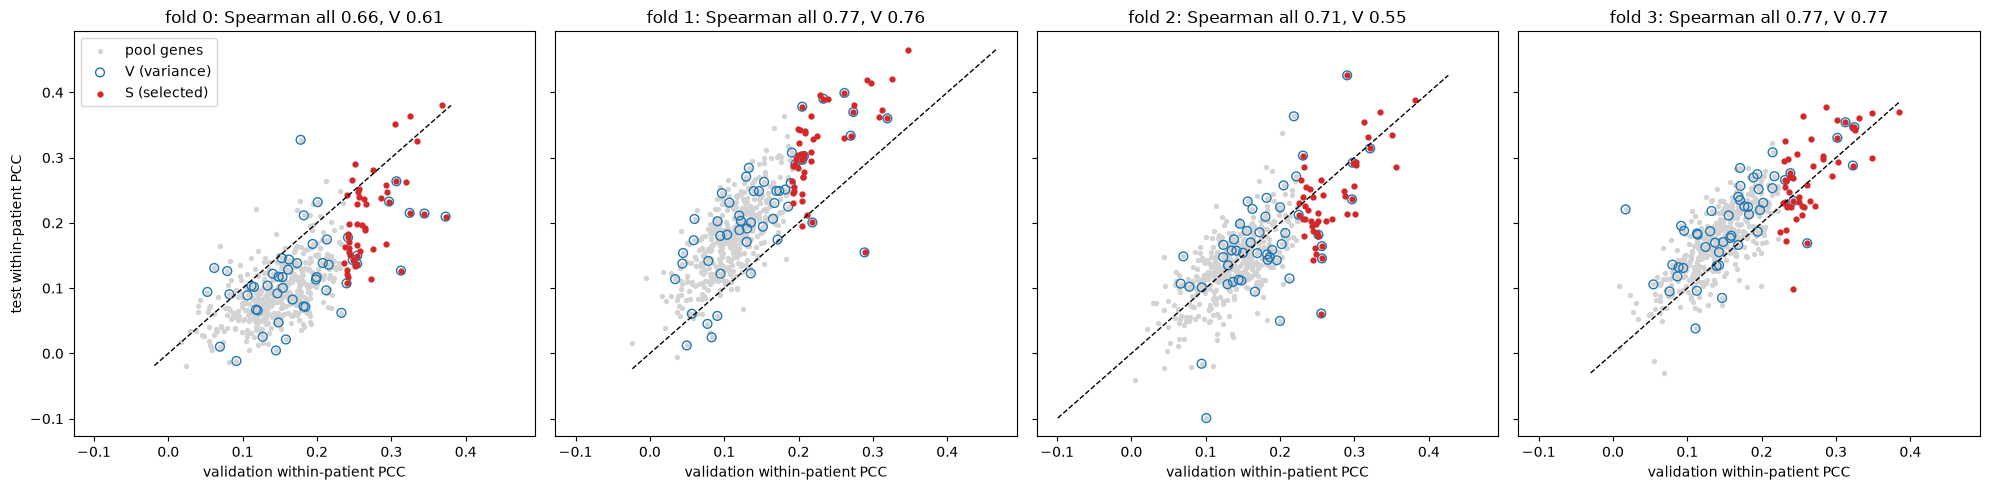

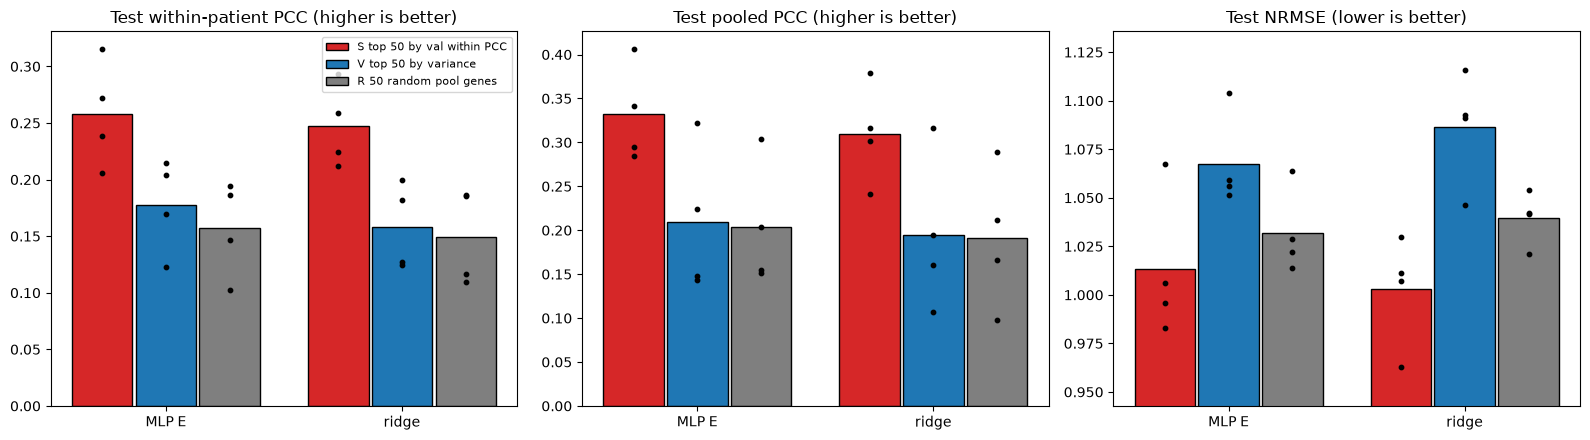

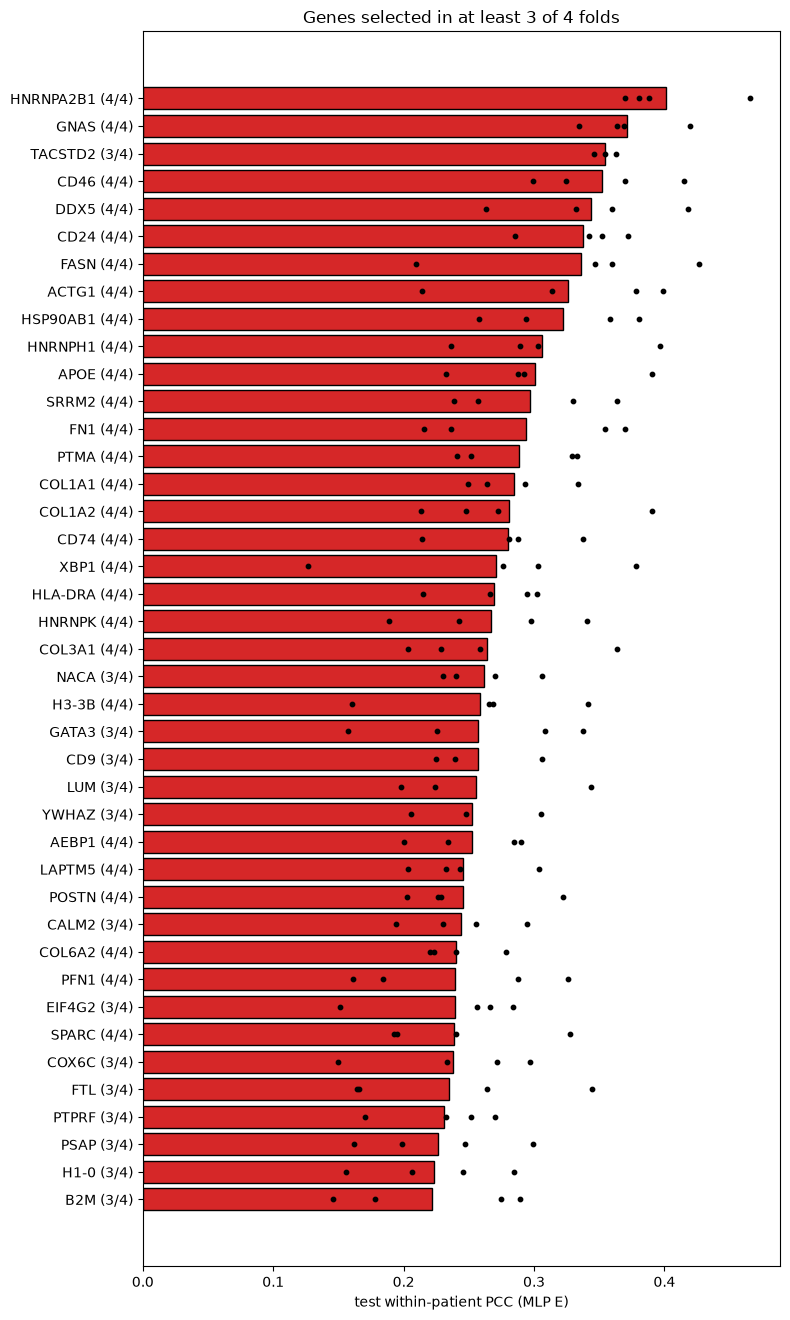

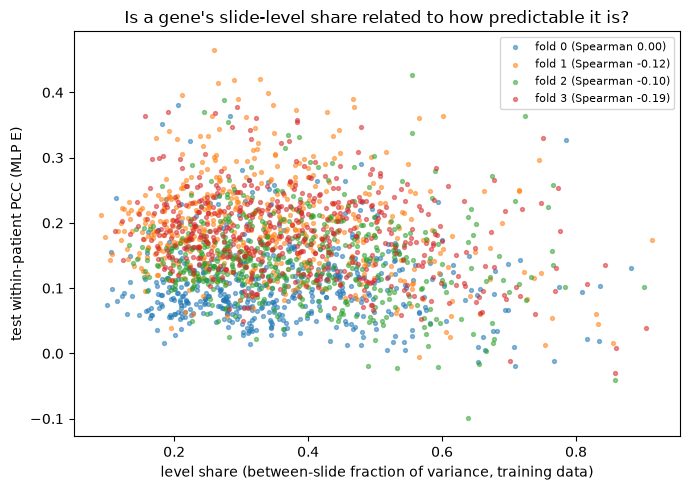

In [19]:
fig, axes = plt.subplots(1, N_FOLDS, figsize=(20, 5), sharex=True, sharey=True)
for fold, ax in enumerate(axes):
    t = gene_table[gene_table["fold"] == fold]
    ax.scatter(t["val_within_PCC"], t["mlp_within_PCC"], s=8, color="lightgrey", label="pool genes")
    v = t[t["in_V"]]
    ax.scatter(v["val_within_PCC"], v["mlp_within_PCC"], s=40, facecolors="none", edgecolors="tab:blue", label="V (variance)")
    s = t[t["in_S"]]
    ax.scatter(s["val_within_PCC"], s["mlp_within_PCC"], s=12, color="tab:red", label="S (selected)")
    low = min(t["val_within_PCC"].min(), t["mlp_within_PCC"].min())
    high = max(t["val_within_PCC"].max(), t["mlp_within_PCC"].max())
    ax.plot([low, high], [low, high], color="black", linestyle="--", linewidth=1)
    row = stability[stability["fold"] == fold].iloc[0]
    ax.set_title(f"fold {fold}: Spearman all {row['val_vs_test_within_all_pool']:.2f}, V {row['val_vs_test_within_V']:.2f}")
    ax.set_xlabel("validation within-patient PCC")
axes[0].set_ylabel("test within-patient PCC")
axes[0].legend(loc="upper left")
plt.tight_layout()
save_figure("1_val_vs_test.png")
plt.show()

set_colors = {"S": "tab:red", "V": "tab:blue", "R": "tab:gray"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
width = 0.27
for ax, metric, title in [(axes[0], "within_PCC", "Test within-patient PCC (higher is better)"),
                          (axes[1], "pooled_PCC", "Test pooled PCC (higher is better)"),
                          (axes[2], "NRMSE", "Test NRMSE (lower is better)")]:
    for m, model in enumerate(["mlp", "ridge"]):
        for g, gene_set in enumerate(GENE_SET_NAMES):
            values = set_fold_scores[(set_fold_scores["model"] == model)
                                     & (set_fold_scores["gene_set"] == gene_set)].sort_values("fold")[metric]
            x = m + (g - 1) * width
            ax.bar(x, values.mean(), width * 0.95, color=set_colors[gene_set], edgecolor="black",
                   label=GENE_SET_NAMES[gene_set] if m == 0 else None)
            ax.scatter(np.full(len(values), x), values, color="black", s=10, zorder=3)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["MLP E", "ridge"])
    ax.set_title(title)
nrmse_values = set_fold_scores[set_fold_scores["model"].isin(["mlp", "ridge"])]["NRMSE"]
axes[2].set_ylim(nrmse_values.min() - 0.02, nrmse_values.max() + 0.02)
axes[0].legend(fontsize=8)
plt.tight_layout()
save_figure("2_selection_comparison.png")
plt.show()

fig, ax = plt.subplots(figsize=(8, max(3, 0.3 * len(stable_genes) + 1)))
order = stable_genes.sort_values("mean_test_within_PCC")
for i, (_, gene) in enumerate(order.iterrows()):
    values = gene_table.loc[gene_table["ensembl_id"] == gene["ensembl_id"], "mlp_within_PCC"]
    ax.barh(i, gene["mean_test_within_PCC"], color="tab:red", edgecolor="black")
    ax.scatter(values, np.full(len(values), i), color="black", s=10, zorder=3)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{s} ({n}/4)" for s, n in zip(order["symbol"], order["folds_selected"])])
ax.set_xlabel("test within-patient PCC (MLP E)")
ax.set_title(f"Genes selected in at least {STABLE_FOLDS} of 4 folds")
plt.tight_layout()
save_figure("3_stable_genes.png")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for fold in range(N_FOLDS):
    t = gene_table[gene_table["fold"] == fold]
    rho = stability.loc[stability["fold"] == fold, "level_share_vs_test_within_mlp"].iloc[0]
    ax.scatter(t["level_share"], t["mlp_within_PCC"], s=8, alpha=0.5, label=f"fold {fold} (Spearman {rho:.2f})")
ax.set_xlabel("level share (between-slide fraction of variance, training data)")
ax.set_ylabel("test within-patient PCC (MLP E)")
ax.set_title("Is a gene's slide-level share related to how predictable it is?")
ax.legend(fontsize=8)
plt.tight_layout()
save_figure("4_level_share_vs_pcc.png")
plt.show()

## Step 12. Best check (report only)

The usual rule: validation PCC higher than the current MLP_JK_Best's and validation NRMSE no worse than the mean predictor's. Two caveats make this a report only: the scores here are on **different genes** than the current Best's 50, and **S's validation PCC is inflated**, because S was picked by validation scores. **This notebook does not change MLP_JK_Best.**

In [20]:
best_summary = pd.read_csv(os.path.join(BEST_DIR, "summary.csv"))
best_row = best_summary[best_summary["val_PCC"].notna() & ~best_summary["model"].str.contains("logged")].iloc[0]
best_val_PCC = best_row["val_PCC"]
print(f"Current MLP_JK_Best ({best_row['model']}): validation PCC {best_val_PCC:.4f}\n")

best_rows = []
for gene_set, name in GENE_SET_NAMES.items():
    row = selection_summary[(selection_summary["model"] == MODEL_NAMES["mlp"]) & (selection_summary["gene_set"] == name)].iloc[0]
    passes = row["val_NRMSE"] <= row["val_mean_predictor_NRMSE"]
    best_rows.append({
        "model": MODEL_NAMES["mlp"], "gene_set": name,
        "val_PCC": row["val_pooled_PCC"], "val_NRMSE": row["val_NRMSE"],
        "val_mean_predictor_NRMSE": row["val_mean_predictor_NRMSE"],
        "passes_NRMSE_rule": passes, "current_best_val_PCC": best_val_PCC,
        "would_beat_best": passes and row["val_pooled_PCC"] > best_val_PCC,
        "note": "different genes than the current Best" + ("; inflated, S was picked on validation" if gene_set == "S" else ""),
    })
best_check = pd.DataFrame(best_rows)
print(best_check.round(4).to_string(index=False))
print("\nMLP_JK_Best is NOT changed by this notebook.")

Current MLP_JK_Best (E 5x5 average): validation PCC 0.2256

                       model                   gene_set  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes_NRMSE_rule  current_best_val_PCC  would_beat_best                                                                        note
E 5x5 average, 500-gene pool S top 50 by val within PCC   0.3427     0.9996                    1.0593               True                0.2256             True different genes than the current Best; inflated, S was picked on validation
E 5x5 average, 500-gene pool       V top 50 by variance   0.2466     1.0825                    1.1128               True                0.2256             True                                       different genes than the current Best
E 5x5 average, 500-gene pool     R 50 random pool genes   0.2175     1.0364                    1.0596               True                0.2256            False                                       different genes than the current B

## Step 13. Save results and add them to the log

`all_results.csv` gets one row per model and gene set (`target` = raw). `val_PCC` is the validation pooled PCC averaged over the set's genes (MLP only). If this notebook is run again, its old rows are replaced instead of duplicated.

In [21]:
gene_pool.to_csv(os.path.join(OUT_DIR, "gene_pool.csv"), index=False)
gene_table.to_csv(os.path.join(OUT_DIR, "gene_scores.csv"), index=False)
selection_comparison.to_csv(os.path.join(OUT_DIR, "selection_comparison.csv"), index=False)
set_comparisons.to_csv(os.path.join(OUT_DIR, "selection_differences.csv"), index=False)
s_v_overlap.to_csv(os.path.join(OUT_DIR, "s_v_overlap.csv"), index=False)
stable_genes.to_csv(os.path.join(OUT_DIR, "stable_genes.csv"), index=False)
per_gene.to_csv(os.path.join(OUT_DIR, "per_gene_summary.csv"), index=False)
stability.to_csv(os.path.join(OUT_DIR, "stability.csv"), index=False)
marker_table.to_csv(os.path.join(OUT_DIR, "markers_in_pool.csv"))
chosen_settings.to_csv(os.path.join(OUT_DIR, "chosen_settings.csv"), index=False)
best_check.to_csv(os.path.join(OUT_DIR, "best_check.csv"), index=False)

settings = {
    "notebook": NOTEBOOK_NAME,
    "min_detection": MIN_DETECTION,
    "pool_size": POOL_SIZE,
    "set_size": SET_SIZE,
    "n_random_draws": N_RANDOM_DRAWS,
    "stable_folds": STABLE_FOLDS,
    "markers": MARKERS,
    "neighbor_distance": NEIGHBOR_DISTANCE,
    "n_pcs": N_PCS,
    "n_folds": N_FOLDS,
    "n_inner_folds": N_INNER_FOLDS,
    "alphas": [float(a) for a in ALPHAS],
    "min_test_sd": MIN_TEST_SD,
    "seed": SEED,
    "hidden_size": HIDDEN_SIZE,
    "dropout": DROPOUT,
    "weight_decay": WEIGHT_DECAY,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "shrink_factors": SHRINK_FACTORS,
    "n_val_groups": N_VAL_GROUPS,
    "n_final_seeds": N_FINAL_SEEDS,
    "device": str(device),
    "torch_version": torch.__version__,
}
with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump(settings, f, indent=2)

if LOG_RESULTS:
    today = datetime.date.today().isoformat()
    log_rows = []
    for _, row in selection_summary.iterrows():
        log_rows.append({
            "notebook": NOTEBOOK_NAME,
            "condition": f"{row['model']} | {row['gene_set']}",
            "pooled_PCC": row["pooled_PCC"],
            "within_patient_PCC": row["within_PCC"],
            "NRMSE": row["NRMSE"],
            "mean_predictor_NRMSE": row["mean_predictor_NRMSE"],
            "val_PCC": row.get("val_pooled_PCC", np.nan),
            "val_NRMSE": row.get("val_NRMSE", np.nan),
            "date": today,
            "target": "raw",
        })
    new_rows = pd.DataFrame(log_rows)
    old_rows = pd.read_csv(RESULTS_LOG)
    old_rows = old_rows[old_rows["notebook"] != NOTEBOOK_NAME]
    new_rows = pd.concat([old_rows, new_rows], ignore_index=True)
    new_rows.to_csv(RESULTS_LOG, index=False)
    print(new_rows.tail(6).round(4).to_string(index=False))

print("\nSaved to", OUT_DIR)
for name in sorted(os.listdir(OUT_DIR)):
    print("  ", name)

 notebook                                                 condition  pooled_PCC  within_patient_PCC  NRMSE  mean_predictor_NRMSE  val_PCC  val_NRMSE       date target
MLP_JK_08 E 5x5 average, 500-gene pool | S top 50 by val within PCC      0.3318              0.2578 1.0131                1.0671   0.3427     0.9996 2026-11-19    raw
MLP_JK_08       E 5x5 average, 500-gene pool | V top 50 by variance      0.2094              0.1777 1.0676                1.0980   0.2466     1.0825 2026-11-19    raw
MLP_JK_08     E 5x5 average, 500-gene pool | R 50 random pool genes      0.2032              0.1575 1.0320                1.0566   0.2175     1.0364 2026-11-19    raw
MLP_JK_08     ridge raw, 500-gene pool | S top 50 by val within PCC      0.3098              0.2474 1.0028                1.0671      NaN        NaN 2026-11-19    raw
MLP_JK_08           ridge raw, 500-gene pool | V top 50 by variance      0.1945              0.1582 1.0863                1.0980      NaN        NaN 2026-11-19    ra

## Summary in plain words: which genes can the images predict?

**Setup check**
- The 299 `__ambiguous[...]` bins were removed.
- 5,366–6,130 genes per fold are expressed in ≥ 10% of training spots; the pool is the top 500 of those by variance.
- 11,350 of 11,488 genes got an HGNC symbol (the other 138 keep their Ensembl ID). The table is saved as `results/gene_symbols.csv` for later notebooks.
- Genes were picked on validation patients only; test patients were used only for scoring.

### What each score means

| Score | What it means | Good vs. bad |
|---|---|---|
| **Within-patient PCC** | Correlation between predicted and true expression **inside one patient** (does the model find where in the tissue the gene is high?), averaged over patients | Higher is better; 0 = no relation |
| **Pooled PCC** | The same correlation over all test spots together (also rewards getting differences **between** patients and slides right) | Higher is better |
| **NRMSE** | Error ÷ the gene's spread | Lower is better; below the mean predictor = better than guessing the average |
| **MSE ratio** | Model error ÷ the error of always guessing the training average, on the same genes | Below 1 = better than guessing |
| **Level share** | Fraction of a gene's variance that is **between slides** (training data) | High = the gene mostly differs from slide to slide, not inside the tissue |

A difference is called **real** if it holds in at least 3 of 4 folds and is bigger than the seed spread.

### 1. Picking genes on validation works on new patients

Test scores, averaged over 50 genes and 4 folds (the same trained models for every gene set):

| Gene set | MLP within-patient PCC | MLP pooled PCC | MLP NRMSE | MLP MSE ratio | Ridge within-patient PCC | Ridge pooled PCC | Ridge NRMSE | Ridge MSE ratio |
|---|---|---|---|---|---|---|---|---|
| **S** top 50 by validation within-patient PCC | **0.258** | **0.332** | **1.013** | **0.896** | **0.247** | **0.310** | **1.003** | **0.879** |
| **V** top 50 by variance (usual list) | 0.178 | 0.209 | 1.068 | 0.947 | 0.158 | 0.195 | 1.086 | 0.970 |
| **R** 50 random pool genes | 0.158 | 0.203 | 1.032 | 0.952 | 0.149 | 0.191 | 1.040 | 0.966 |

- **S beats V and R by a lot, and it's real.** Within-patient PCC is +0.08 over V and +0.10 over R (MLP), better in 4 of 4 folds and far above the seed spread (≤ 0.005). Pooled PCC, NRMSE and MSE ratio agree; NRMSE is better in 3 of 4 folds. Ridge shows the same picture, so this is about the **genes**, not about the MLP.
- **There's no sign that S was just lucky on validation.** S's mean validation within-patient PCC (0.259) is the same as its test value (0.258). Across all 500 pool genes, validation and test predictability correlate strongly (Spearman 0.66–0.77 per fold; 0.55–0.77 for the V genes alone; Figure 1).
- **The usual list (V) is a poor choice for this task.** V and S share only 8–11 of 50 genes per fold. High variance often comes from genes that differ between patients or slides, or that the images don't show. V's weakest genes include ANPEP, MGP, S100A8, KRT18 and MUC1 (test within-patient PCC < 0.11).
- **ridge ≈ MLP** on these genes (S: 0.247 vs. 0.258 within-patient). The images' signal for the predictable genes is mostly linear.

### 2. The predictable genes are consistent across folds

Different folds pick largely the same genes: 34–39 of 50 shared between any two folds. **41 genes are selected in at least 3 of 4 folds, 27 in all 4** (`stable_genes.csv`, Figure 3). Their test within-patient PCC is 0.22–0.40.

What kind of genes they are:

| Group | Consistently predictable genes |
|---|---|
| **Stroma / extracellular matrix** | COL1A1, COL1A2, COL3A1, COL6A2, LUM, POSTN, SPARC, FN1, AEBP1 |
| **Tumor / epithelial (luminal breast)** | TACSTD2, CD24, GATA3, XBP1, FASN, CD9, PTPRF |
| **Immune / antigen presentation, macrophages** | CD74, HLA-DRA, LAPTM5, B2M, PSAP, FTL |
| **"How many cells are here" genes** (high in every dense, active cell; RNA processing, protein synthesis, chromatin) | HNRNPA2B1, HNRNPH1, HNRNPK, DDX5, SRRM2, PTMA, NACA, EIF4G2, HSP90AB1, ACTG1, PFN1, H3-3B, H1-0, CALM2, YWHAZ, GNAS, CD46, COX6C, APOE |
| **Fat** | none |

- The **top** of the list is the "cell density" group (HNRNPA2B1, 0.40), which makes sense: H&E shows directly how densely packed the nuclei are.
- **Stroma** (collagens) and **tumor epithelium** (TACSTD2, CD24, GATA3, XBP1) are next; tissue type is what H&E shows best.
- **Fat markers can't be tested here:** LPL and PLIN4 are detected in only 4–8% of spots (filtered out), ADIPOQ isn't in the data, and PTPRC (immune) is filtered too. Fat has few cells and few reads.
- **Known markers:** COL1A1, COL3A1, POSTN, CD74 were picked in 4/4 folds; GATA3, LUM in 3/4. **ERBB2 and KRT19** are in V in every fold but only picked once: they are highly variable mostly **between** patients (level share 0.74 / 0.73; HER2 status), so their within-patient PCC is modest (0.22) even though their pooled PCC is high (0.48 / 0.28). KRT8 is weak (0.16). EPCAM never made the pool.

### 3. Does a gene's slide-level share explain predictability?

Only a little. Across pool genes, Spearman between level share and test within-patient PCC is −0.10 on average for the MLP (−0.19 to 0.00 per fold) and −0.16 for ridge; for pooled PCC it's about −0.07 / −0.11 (Figure 4). Genes that vary mostly between slides are slightly harder to predict inside a patient, but level share is not the main reason a gene is or isn't predictable.

### Best model

`best_check.csv` shows S (validation PCC 0.343) and even V (0.247) above the current Best (0.226), but these are on **different genes** (V here has the ambiguous bins and rarely expressed genes removed), and S's value is picked on validation. **MLP_JK_Best was not changed**; whether to switch the gene list is your call.

### Bottom line

Yes, some genes are clearly predictable from H&E, and choosing them on validation patients carries over to new patients almost one-to-one. They are stroma, tumor epithelium, immune/macrophage genes, and genes that track how many cells are in a spot. The top-50-by-variance list hides them: about 80% of the predictable set is outside it.